# 1. Data Exploration & Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Dataset Head:
   class                                              tweet
0      2  !!! RT @mayasolovely: As a woman you shouldn't...
1      1  !!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2      1  !!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3      1  !!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4      1  !!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   class   24783 non-null  int64 
 1   tweet   24783 non-null  object
dtypes: int64(1), object(1)
memory usage: 387.4+ KB
None


/tmp/ipython-input-3644557926.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=df, palette='viridis')


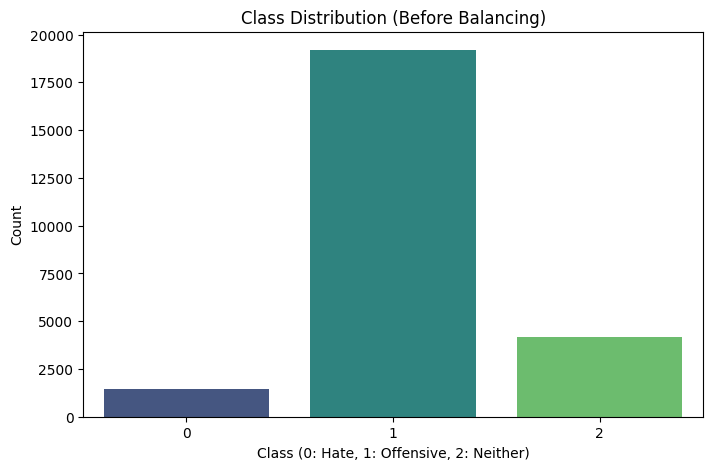


Class Counts:
 class
1    19190
2     4163
0     1430
Name: count, dtype: int64


In [ ]:
# Load the Dataset
dataset_url = "https://media.geeksforgeeks.org/wp-content/uploads/20250321123144355200/Dataset---Hate-Speech-Detection-using-Deep-Learning.csv"
df = pd.read_csv(dataset_url)

# Inspect the Data
print("Dataset Head:")
print(df.head())
print("\nDataset Info:")
print(df.info())

# Visualize Class Distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='class', data=df, palette='viridis')
plt.title('Class Distribution (Before Balancing)')
plt.xlabel('Class (0: Hate, 1: Offensive, 2: Neither)')
plt.ylabel('Count')
plt.show()

# Check actual counts
print("\nClass Counts:\n", df['class'].value_counts())

# 2. Data Cleaning & Processing + Model Training


 Objective: Clean the text (remove stopwords, punctuation, stem) , balance the dataset, and convert text to numbers (tokenization).

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
import random
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D, Bidirectional
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# Setup Resources
twitter_stopwords = {'rt', 'amp'}
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4') # Open Multilingual Wordnet
stop_words = set(stopwords.words('english'))
stop_words.update(twitter_stopwords)
stemmer = PorterStemmer()

# 1. Cleaning the Text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    words = text.split()
    words = [stemmer.stem(w) for w in words if w not in stop_words]
    return " ".join(words)

df['clean_tweet'] = df['tweet'].apply(clean_text)

# 2. Train-Test-Val Split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    df['clean_tweet'], df['class'], test_size=0.2, random_state=42, stratify=df['class']
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full
)

# 3. Data Augmentation to Balance Classes
print(f"Original Training Shape: {X_train.shape}")
print("Class distribution before augmentation:\n", y_train.value_counts())

def get_synonyms(word):
    """Get a set of synonyms for a word from WordNet."""
    synonyms = set()
    for syn in wordnet.synsets(word):
        for lemma in syn.lemmas():
            candidate = lemma.name().replace("_", " ").lower()
            if candidate != word and len(candidate.split()) == 1: # Avoid phrases
                synonyms.add(candidate)
    return list(synonyms)

def augment_text(text, num_replacements=1):
    """Replace 'num_replacements' words in the text with synonyms."""
    words = text.split()
    if len(words) < 3: return text # Skip very short tweets

    new_words = words.copy()
    random_indices = random.sample(range(len(words)), min(len(words), num_replacements))

    for idx in random_indices:
        word = words[idx]
        syns = get_synonyms(word)
        if syns:
            new_words[idx] = random.choice(syns)

    return " ".join(new_words)

# Combine X and y temporarily to manage sampling
train_df = pd.DataFrame({'text': X_train, 'label': y_train})

# Find the majority class count
max_count = train_df['label'].value_counts().max()
augmented_rows = []

print("\nStarting Augmentation (this may take a moment)...")

for class_id in train_df['label'].unique():
    class_df = train_df[train_df['label'] == class_id]
    current_count = len(class_df)

    if current_count < max_count:
        target_count = max_count - current_count
        print(f"  -> Augmenting Class {class_id}: Generating {target_count} new samples...")

        # Randomly sample existing texts to augment
        texts_to_augment = np.random.choice(class_df['text'].values, target_count, replace=True)

        for text in texts_to_augment:
            # Create a variation
            aug_text = augment_text(text, num_replacements=2)
            augmented_rows.append({'text': aug_text, 'label': class_id})
    else:
        print(f"  -> Class {class_id} is the majority ({current_count}). No augmentation needed.")

# Append new data
if augmented_rows:
    aug_df = pd.DataFrame(augmented_rows)
    train_df = pd.concat([train_df, aug_df], axis=0)

# Shuffle the dataset
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Update X_train and y_train
X_train = train_df['text']
y_train = train_df['label']

print("\nFinal Training Shape:", X_train.shape)
print("Class distribution after augmentation:\n", y_train.value_counts())


# 4. Tokenization and Padding
MAX_WORDS = 5000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train) # Fit on the NEW augmented data

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='pre', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_LEN, padding='pre', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='pre', truncating='post')

# Encode Labels
y_train_enc = to_categorical(y_train, num_classes=3)
y_val_enc = to_categorical(y_val, num_classes=3)
y_test_enc = to_categorical(y_test, num_classes=3)


# 5. Define the Model
model = Sequential()
model.add(Embedding(input_dim=MAX_WORDS, output_dim=128))
model.add(SpatialDropout1D(0.3))
model.add(Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.3)))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(3, activation='softmax'))

optimizer = Adam(learning_rate=0.0001)
model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

# 6. Callbacks
callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]

# 7. Training
print("\nStarting Training with Augmented Data...")
history = model.fit(
    X_train_pad, y_train_enc,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_pad, y_val_enc),
    # Removed class_weight since data is now balanced
    callbacks=callbacks,
    verbose=1
)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Original Training Shape: (15860,)
Class distribution before augmentation:
 class
1    12281
2     2664
0      915
Name: count, dtype: int64

Starting Augmentation (this may take a moment)...
  -> Class 1 is the majority (12281). No augmentation needed.
  -> Augmenting Class 0: Generating 11366 new samples...
  -> Augmenting Class 2: Generating 9617 new samples...

Final Training Shape: (36843,)
Class distribution after augmentation:
 label
0    12281
1    12281
2    12281
Name: count, dtype: int64

Starting Training with Augmented Data...
Epoch 1/20
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 675s 567ms/step - accuracy: 0.5283 - loss: 0.9491 - val_accuracy: 0.8205 - val_loss: 0.4633 - learning_rate: 1.0000e-04
Epoch 2/20
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 640s 555ms/step - accuracy: 0.8724 - loss: 0.3667 - val_accuracy: 0.8472 - val_loss: 0.4095 - learning_rate: 1.0000e-04
Epoch 3/20
1152/1152 ━━━━━━━━━━━━━━━━━━━━ 676s 551ms/step - accuracy: 0.9164 - loss: 0.2580 - val_accuracy: 0.8676 - val_loss: 0.38

# 3. Visualizing Tokenizer Results

In [8]:
word_index = tokenizer.word_index # Dictionary of all words {word: rank}
total_vocab = len(word_index)

print(f"\n--- VOCABULARY ANALYSIS ---")
print(f"Total Unique Words in Training: {total_vocab}")
print(f"Max Words Allowed:              {MAX_WORDS}")
print(f"Words Dropped (OOV):            {max(0, total_vocab - MAX_WORDS)}")

# Sort words by frequency (rank)
sorted_words = sorted(word_index.items(), key=lambda item: item[1])

print(f"\nTop 10 Most Frequent Words (Kept):")
for word, rank in sorted_words[:10]:
    print(f"  #{rank}: {word}")

print(f"\n--- THE CUT-OFF ZONE (Rank {MAX_WORDS-5} to {MAX_WORDS+5}) ---")
# Check words right at the border of 5000
start_idx = max(0, MAX_WORDS - 6)
end_idx = min(total_vocab, MAX_WORDS + 5)

for i in range(start_idx, end_idx):
    if i < len(sorted_words):
        word, rank = sorted_words[i]
        status = "KEPT" if rank < MAX_WORDS else "DROPPED"
        print(f"  #{rank} [{status}]: {word}")

print("\n--- CHECKING SPECIFIC OFFENSIVE ROOTS ---")
# Check typical offensive roots to see if they survived (Stemmed versions)
check_list = ['kill', 'hate', 'stupid', 'idiot', 'nasti', 'ugli']
for w in check_list:
    if w in word_index:
        rank = word_index[w]
        status = "KEPT" if rank < MAX_WORDS else "DROPPED"
        print(f"  '{w}': Rank #{rank} -> {status}")
    else:
        print(f"  '{w}': Not found in dataset")
print("========================================================\n")


--- VOCABULARY ANALYSIS ---
Total Unique Words in Training: 30338
Max Words Allowed:              5000
Words Dropped (OOV):            25338

Top 10 Most Frequent Words (Kept):
  #1: <OOV>
  #2: bitch
  #3: like
  #4: hoe
  #5: fuck
  #6: nigga
  #7: trash
  #8: im
  #9: dont
  #10: get

--- THE CUT-OFF ZONE (Rank 4995 to 5005) ---
  #4995 [KEPT]: midterm
  #4996 [KEPT]: corrupt
  #4997 [KEPT]: explod
  #4998 [KEPT]: kmdk83
  #4999 [KEPT]: beautifulmin
  #5000 [DROPPED]: rubi
  #5001 [DROPPED]: gonow
  #5002 [DROPPED]: suckhow
  #5003 [DROPPED]: nowh
  #5004 [DROPPED]: girardi
  #5005 [DROPPED]: 128073yost

--- CHECKING SPECIFIC OFFENSIVE ROOTS ---
  'kill': Rank #67 -> KEPT
  'hate': Rank #36 -> KEPT
  'stupid': Rank #82 -> KEPT
  'idiot': Rank #674 -> KEPT
  'nasti': Rank #387 -> KEPT
  'ugli': Rank #114 -> KEPT



# 4. Plot Loss and Accuracy Curves

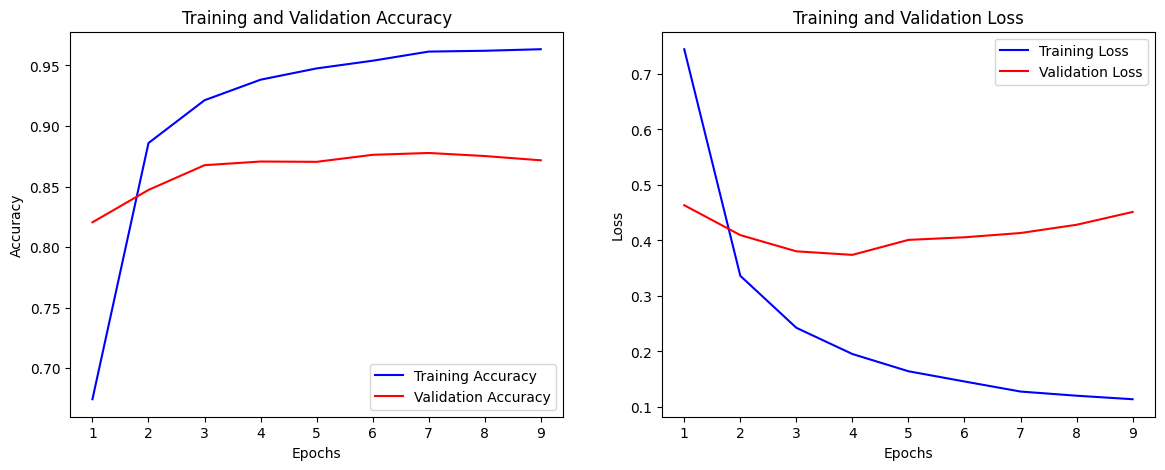


Model saved successfully as 'hate_speech_bilstm_augmented.keras'


In [ ]:
import matplotlib.pyplot as plt

# Plot Loss & Accuracy Curves
def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b-', label='Training Loss')
    plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

plot_training_history(history)

# Save the Model
model_name = 'hate_speech_bilstm_augmented.keras'
model.save(model_name)
print(f"\nModel saved successfully as '{model_name}'")

# 5. Model Evaluation

155/155 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step

Classification Report:

               precision    recall  f1-score   support

     Hate (0)       0.37      0.38      0.37       286
Offensive (1)       0.95      0.91      0.93      3838
  Neither (2)       0.78      0.91      0.84       833

     accuracy                           0.88      4957
    macro avg       0.70      0.74      0.71      4957
 weighted avg       0.89      0.88      0.88      4957



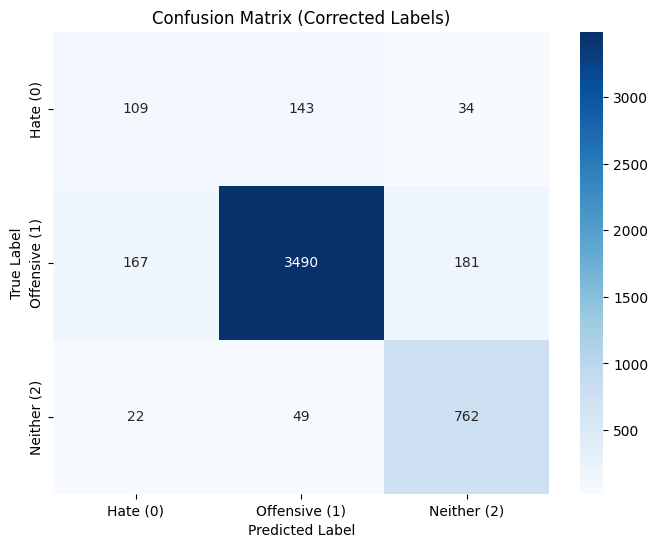

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report


# 1. Generate Predictions
y_pred_probs = model.predict(X_test_pad)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test_enc, axis=1)

# 2. Define the Correct Labels
# 0 = Hate, 1 = Offensive (Majority), 2 = Neither
class_names = ['Hate (0)', 'Offensive (1)', 'Neither (2)']

# 3. Print Classification Report
print("\nClassification Report:\n")
print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

# 4. Plot Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix (Corrected Labels)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()


       MODEL PERFORMANCE REPORT

--- Hyperparameters Explored ---
Embedding Dim:      128
Sequence Length:    100
LSTM Units:         64 (Bidirectional)
Dropout Rates:      0.3 (Spatial, Standard, Recurrent)
Optimizer:          Adam (Learning Rate: 0.0001)
Batch Size:         32
Class Weights:      Balanced
------------------------------

Evaluating on TRAIN set...
Train Accuracy: 0.9577
Evaluating on TEST set...
Test Accuracy:  0.8798
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step

--- Classification Report (Test Set) ---
              precision    recall  f1-score   support

           0       0.37      0.38      0.37       286
           1       0.95      0.91      0.93      3838
           2       0.78      0.91      0.84       833

    accuracy                           0.88      4957
   macro avg       0.70      0.74      0.71      4957
weighted avg       0.89      0.88      0.88      4957



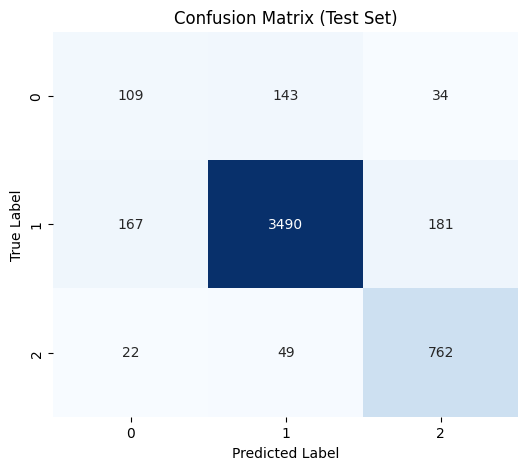

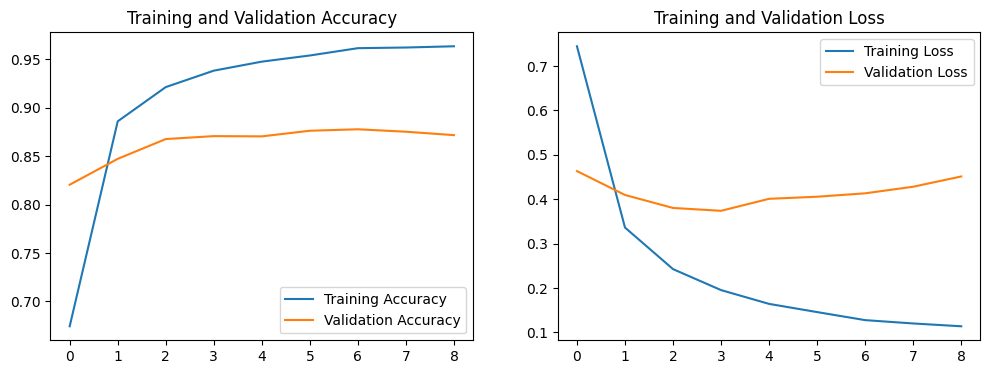

In [ ]:
# Evaluation Function
def evaluation(model_source, X_train, y_train, X_test, y_test, history=None):
    """
    Loads a model (or takes an existing one), evaluates performance,
    plots history, and prints a report for hyperparameters.
    """
    # 1. Load Model (if a path is passed) or use existing object
    if isinstance(model_source, str):
        from tensorflow.keras.models import load_model
        print(f"Loading model from {model_source}...")
        model = load_model(model_source)
    else:
        model = model_source

    print("\n" + "="*40)
    print("       MODEL PERFORMANCE REPORT")
    print("="*40)

    # 2. Print Hyperparameters
    print("\n--- Hyperparameters Explored ---")
    print(f"Embedding Dim:      128")
    print(f"Sequence Length:    100")
    print(f"LSTM Units:         64 (Bidirectional)")
    print(f"Dropout Rates:      0.3 (Spatial, Standard, Recurrent)")
    print(f"Optimizer:          Adam (Learning Rate: 0.0001)")
    print(f"Batch Size:         32")
    print(f"Class Weights:      Balanced")
    print("-" * 30)

    # 3. Evaluate on TRAIN set
    print("\nEvaluating on TRAIN set...")
    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    print(f"Train Accuracy: {train_acc:.4f}")

    # 4. Evaluate on TEST set
    print("Evaluating on TEST set...")
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"Test Accuracy:  {test_acc:.4f}")

    # 5. Predictions & Metrics
    # Convert one-hot encoded labels back to single integers for metrics
    y_test_true = np.argmax(y_test, axis=1)
    y_pred_probs = model.predict(X_test)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)

    print("\n--- Classification Report (Test Set) ---")
    print(classification_report(y_test_true, y_pred_classes))

    # 6. Plot Confusion Matrix
    plt.figure(figsize=(6, 5))
    cm = confusion_matrix(y_test_true, y_pred_classes)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title('Confusion Matrix (Test Set)')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

    # 7. Plot Learning Curves
    if history:
        acc = history.history['accuracy']
        val_acc = history.history['val_accuracy']
        loss = history.history['loss']
        val_loss = history.history['val_loss']
        epochs_range = range(len(acc))

        plt.figure(figsize=(12, 4))

        # Accuracy Plot
        plt.subplot(1, 2, 1)
        plt.plot(epochs_range, acc, label='Training Accuracy')
        plt.plot(epochs_range, val_acc, label='Validation Accuracy')
        plt.legend(loc='lower right')
        plt.title('Training and Validation Accuracy')

        # Loss Plot
        plt.subplot(1, 2, 2)
        plt.plot(epochs_range, loss, label='Training Loss')
        plt.plot(epochs_range, val_loss, label='Validation Loss')
        plt.legend(loc='upper right')
        plt.title('Training and Validation Loss')
        plt.show()


evaluation(model, X_train_pad, y_train_enc, X_test_pad, y_test_enc, history)



In [ ]:
def run_terminal_demo():
    label_map = {0: 'Hate: Class 0', 1: 'Offensive Class 1', 2: 'Neither: Class 2'}

    print("\n" + "="*50)
    print("      LIVE PREDICTION TERMINAL")
    print("      Type 'exit' or 'q' to stop.")
    print("="*50)

    while True:
        user_input = input("\nEnter a sentence: ")

        if user_input.lower() in ['exit', 'q', 'quit']:
            print("Exiting...")
            break

        # 1. Clean the Input
        cleaned_text = clean_text(user_input)

        # 2. Tokenize and Pad
        seq = tokenizer.texts_to_sequences([cleaned_text])
        padded = pad_sequences(seq, maxlen=MAX_LEN, padding='pre', truncating='post')

        # 3. Predict
        prediction_probs = model.predict(padded, verbose=0)
        predicted_class_index = np.argmax(prediction_probs)
        confidence = np.max(prediction_probs)

        # 4. Get readable label
        result_label = label_map.get(predicted_class_index, f"Class {predicted_class_index}")

        print(f"--> Prediction: {result_label}  (Confidence: {confidence:.2%})")

run_terminal_demo()


      LIVE PREDICTION TERMINAL
      Type 'exit' or 'q' to stop.
--> Prediction: Hate: Class 0  (Confidence: 91.20%)
--> Prediction: Hate: Class 0  (Confidence: 80.00%)
--> Prediction: Hate: Class 0  (Confidence: 55.26%)
--> Prediction: Neither: Class 2  (Confidence: 45.25%)
--> Prediction: Hate: Class 0  (Confidence: 55.26%)
--> Prediction: Offensive Class 1  (Confidence: 94.60%)
--> Prediction: Hate: Class 0  (Confidence: 57.84%)
--> Prediction: Hate: Class 0  (Confidence: 68.02%)
--> Prediction: Hate: Class 0  (Confidence: 43.72%)
--> Prediction: Hate: Class 0  (Confidence: 50.97%)
--> Prediction: Hate: Class 0  (Confidence: 43.72%)
--> Prediction: Hate: Class 0  (Confidence: 43.72%)
Exiting...
